# Model 3. Market Value Prediction

Random Forest Regressor оценивает **записанную историческую стоимость** CM по 27 входам Feature Set v1. Далее рассчитываем:

\[\text{ValueGap}=\text{PredictedValue}-\text{MarketValue}\]

Положительный gap — повод для дополнительного скаутинга, **не объективная справедливая цена и не доказательство недооценённости**. Отсутствуют контракты, травмы, агентские условия, спрос и другие факторы. Записанная стоимость также не равна цене трансфера.

Срез: **26.09.2022**. Не используем будущие значения. Рыночная стоимость, FIFA value/wage, overall, potential, имена и ID не являются входами. Цена не добавляется в KNN/K-Means. Единица стоимости — исходная единица архива Transfermarkt; её соответствие EUR не подтверждено.

Протокол: фиксированные 2308 train / 578 test из Step 3; подбор на train через 3-fold CV; оценка на test; **вложенная 5×3 CV** даёт прогноз каждому train-игроку без обучения или подбора параметров на его цене. Test уже изучался в EDA: это диагностический benchmark, не новый независимый финальный тест.


In [1]:
from pathlib import Path
import os
os.environ["LOKY_MAX_CPU_COUNT"]="1"
import sys, json, hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
%matplotlib inline
_limits=threadpool_limits(1)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"config/feature_set_v1.json").exists())
sys.path.insert(0,str(ROOT))
from src.valuation import MarketValuePredictor, VALUE_FEATURES, make_forest_estimator, make_ridge_estimator, value_gap_table
FEATURE_DIR=ROOT/"data/processed/features"
OUT=ROOT/"data/processed/valuation"
REPORT=ROOT/"reports/valuation"
OUT.mkdir(parents=True,exist_ok=True); REPORT.mkdir(parents=True,exist_ok=True)
SEED=42
FEATURES=list(VALUE_FEATURES)
figures=[]
def sha(path): return hashlib.sha256(path.read_bytes()).hexdigest()
def ids_hash(ids): return hashlib.sha256("\n".join(sorted(map(str,ids))).encode()).hexdigest()
def show(fig,name):
    for extension in ["png","svg"]:
        path=REPORT/f"{name}.{extension}"
        fig.savefig(path,dpi=150,bbox_inches="tight")
        if extension=="svg": path.write_text("\n".join(line.rstrip() for line in path.read_text(encoding="utf-8").splitlines())+"\n",encoding="utf-8")
    figures.append(name)
    plt.show(); plt.close(fig)
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"figure.constrained_layout.use":True})


## 1. Данные, признаки и временная целостность

Используем сырые 27 входов, а не ранее глобально преобразованную матрицу. Числовые пропуски и категории обрабатываются **внутри каждого обучающего fold**. RF не требует стандартизации; Ridge получает свой scaler внутри pipeline. Редкие/неизвестные категории поддерживаются без переобучения encoder на test.


In [2]:
fm=json.loads((FEATURE_DIR/"feature_manifest.json").read_text(encoding="utf-8"))
source=FEATURE_DIR/"moneyball_features_2022-09-26.csv"
assert sha(source)==fm["outputs"][source.name]["sha256"]
data=pd.read_csv(source,dtype={"fifa_id":"string","tm_id":"string","league_id":"string"})
train=data.loc[data.split.eq("train")].copy().reset_index(drop=True)
test=data.loc[data.split.eq("test")].copy().reset_index(drop=True)
assert (len(data),len(train),len(test))==(2886,2308,578)
assert data.fifa_id.is_unique and not set(train.fifa_id)&set(test.fifa_id)
split=pd.read_csv(FEATURE_DIR/"player_split.csv",dtype="string")
assert data.set_index("fifa_id").split.astype("string").sort_index().equals(split.set_index("fifa_id").split.sort_index())
validator=MarketValuePredictor()
validator._profiles(data)  # explicit same historical/date/range checks as reusable model
assert pd.to_datetime(data.as_of_date).eq(pd.Timestamp(fm["cutoff"])).all()
assert (pd.Timestamp(fm["cutoff"])-pd.to_datetime(data.market_value_date)).dt.days.between(0,365).all()
assert data.tm_market_value.gt(0).all()
for forbidden in ["tm_market_value","value_eur","wage_eur","overall","potential","fifa_id","tm_id","short_name"]:
    assert forbidden not in FEATURES
X=train[FEATURES]; y=train.tm_market_value.to_numpy(float)
Xt=test[FEATURES]; yt=test.tm_market_value.to_numpy(float)
display(pd.DataFrame({"split":["train","test"],"players":[len(train),len(test)],
                      "median_recorded_value":[np.median(y),np.median(yt)],
                      "missing_numeric_cells":[int(X.select_dtypes("number").isna().sum().sum()),int(Xt.select_dtypes("number").isna().sum().sum())]}))
display(pd.DataFrame({"feature":FEATURES,"role":["numeric" if c not in ["preferred_foot","work_rate_attack","work_rate_defence","league_id"] else "categorical" for c in FEATURES]}))


,split,players,median_recorded_value,missing_numeric_cells
0,train,2308,800000.0,4
1,test,578,750000.0,3


,feature,role
0,attacking_short_passing,numeric
1,skill_long_passing,numeric
2,mentality_vision,numeric
3,skill_ball_control,numeric
4,skill_dribbling,numeric
5,movement_agility,numeric
6,movement_balance,numeric
7,movement_reactions,numeric
8,mentality_composure,numeric
9,power_stamina,numeric


## 2. Train-only подбор и простые контрольные модели

Цель обучения — `log1p(tm_market_value)`: цены сильно асимметричны. Подбор минимизирует MAE в log-пространстве. Обратное преобразование возвращает исходные единицы, но **не оценивает автоматически арифметическое условное среднее**: возможен систематический недопрогноз дорогих игроков. Поэтому оцениваем и log-, и исходную шкалу.

Сравнения: постоянная медиана train и регуляризованная линейная Ridge на тех же 27 входах. Сетка RF фиксирована заранее: leaf ∈ {2,5}, max_features ∈ {0.7,1.0}, 160 деревьев. Test не выбирает настройки и не определяет победителя для дальнейшего fit.


In [3]:
def log_mae(actual,predicted):
    return mean_absolute_error(np.log1p(actual),np.log1p(predicted))
scorer=make_scorer(log_mae,greater_is_better=False)
grid={"regressor__forest__min_samples_leaf":[2,5],"regressor__forest__max_features":[.7,1.]}
def search_forest(features,target):
    return GridSearchCV(make_forest_estimator(),grid,cv=KFold(3,shuffle=True,random_state=SEED),
                        scoring=scorer,n_jobs=1,error_score="raise",return_train_score=False).fit(features,target)
search=search_forest(X,y)
cv_results=pd.DataFrame(search.cv_results_)[["params","mean_test_score","std_test_score","rank_test_score"]]
cv_results["cv_log_mae"]=-cv_results.mean_test_score
cv_results.to_csv(REPORT/"forest_cv.csv",index=False)
display(cv_results.sort_values("rank_test_score"))
selected={"min_samples_leaf":search.best_params_["regressor__forest__min_samples_leaf"],
          "max_features":search.best_params_["regressor__forest__max_features"]}
model=MarketValuePredictor(**selected).fit(train)
pred=model.predict(test)
assert np.allclose(pred,search.best_estimator_.predict(Xt))
ridge_search=GridSearchCV(make_ridge_estimator(),{"regressor__ridge__alpha":[1.,10.,100.]},
                          cv=KFold(3,shuffle=True,random_state=SEED),scoring=scorer,n_jobs=1,error_score="raise").fit(X,y)
median=DummyRegressor(strategy="median").fit(X,y)
predictions={"Train median":median.predict(Xt),"Ridge log":ridge_search.predict(Xt),"Random Forest log":pred}
display(Markdown(f"RF: **{selected}**; Ridge alpha: **{ridge_search.best_params_['regressor__ridge__alpha']}**. Подбор завершён без test."))


,params,mean_test_score,std_test_score,rank_test_score,cv_log_mae
0,"{'regressor__forest__max_features': 0.7, 'regr...",-0.512382,0.012980,1,0.512382
2,"{'regressor__forest__max_features': 1.0, 'regr...",-0.515085,0.014241,2,0.515085
1,"{'regressor__forest__max_features': 0.7, 'regr...",-0.519166,0.015502,3,0.519166
3,"{'regressor__forest__max_features': 1.0, 'regr...",-0.520743,0.014826,4,0.520743


RF: **{'min_samples_leaf': 2, 'max_features': 0.7}**; Ridge alpha: **1.0**. Подбор завершён без test.

## 3. Ошибки на 578 test-игроках

95% bootstrap-интервалы пересэмплируют игроков test при фиксированной обученной модели; не учитывают смену сезона, подбор и вариацию обучения. Все строки независимы по player ID, но экономические зависимости между лигами/клубами остаются. Интервалы описательные, без подтверждающего вывода о будущих рынках.


,MAE,RMSE,R2_raw,MAE_log,R2_log,median_multiplicative_error,mean_gap
model,,,,,,,
Train median,3.284256e+06,7.901859e+06,-0.1472,1.2736,-0.0209,2.7500,-2.830190e+06
Ridge log,1.315547e+06,2.950272e+06,0.8401,0.5088,0.8241,1.5318,-6.955568e+05
Random Forest log,1.333985e+06,3.203745e+06,0.8114,0.4869,0.8392,1.4748,-8.024534e+05


MAE  MAE_log
model             quantile                       
Random Forest log 0.025     1.102377e+06   0.4549
                  0.975     1.573651e+06   0.5210
Ridge log         0.025     1.113654e+06   0.4717
                  0.975     1.534431e+06   0.5457
Train median      0.025     2.712391e+06   1.1945
                  0.975     3.905479e+06   1.3551

Уменьшение log-MAE RF против Ridge: **0.0218**; paired bootstrap 95% CI **[-0.0087, 0.0517]**.

По исходной шкале Ridge: MAE=1,315,547, RMSE=2,950,272; RF: MAE=1,333,985, RMSE=3,203,745. Преимущество по одной шкале не означает универсального превосходства. Интервал разности log-MAE включает ноль: убедительного преимущества RF над Ridge не установлено.

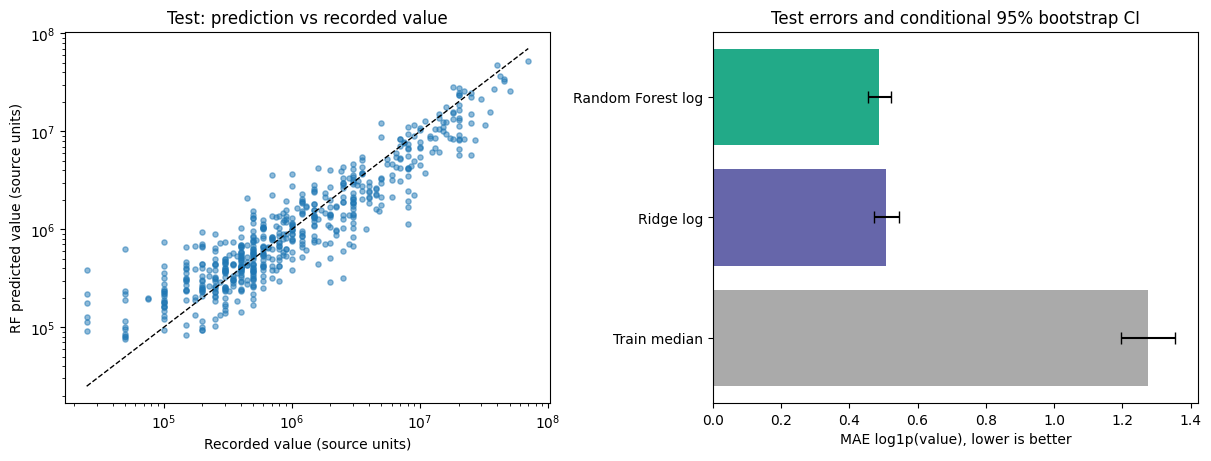

In [4]:
def metrics(actual,predicted):
    error=np.log1p(predicted)-np.log1p(actual)
    return {"MAE":float(mean_absolute_error(actual,predicted)),"RMSE":float(np.sqrt(mean_squared_error(actual,predicted))),
            "R2_raw":float(r2_score(actual,predicted)),"MAE_log":float(np.abs(error).mean()),
            "R2_log":float(r2_score(np.log1p(actual),np.log1p(predicted))),
            "median_multiplicative_error":float(np.exp(np.median(np.abs(error)))),
            "mean_gap":float(np.mean(predicted-actual))}
evaluation=pd.DataFrame({name:metrics(yt,p) for name,p in predictions.items()}).T.rename_axis("model")
evaluation.to_csv(REPORT/"test_metrics.csv")
rng=np.random.default_rng(SEED)
boot_rows=[]; paired=[]
for repeat in range(1000):
    idx=rng.integers(0,len(yt),len(yt))
    for name,p in predictions.items():
        boot_rows.append({"repeat":repeat,"model":name,"MAE":mean_absolute_error(yt[idx],p[idx]),"MAE_log":log_mae(yt[idx],p[idx])})
    paired.append(log_mae(yt[idx],predictions["Ridge log"][idx])-log_mae(yt[idx],pred[idx]))
boot=pd.DataFrame(boot_rows)
intervals=boot.groupby("model")[["MAE","MAE_log"]].quantile([.025,.975]).rename_axis(index=["model","quantile"])
intervals.to_csv(REPORT/"test_metric_intervals.csv")
paired_ci=np.quantile(paired,[.025,.975]).tolist()
display(evaluation.round(4));display(intervals.round(4))
display(Markdown(f"Уменьшение log-MAE RF против Ridge: **{evaluation.loc['Ridge log','MAE_log']-evaluation.loc['Random Forest log','MAE_log']:.4f}**; paired bootstrap 95% CI **[{paired_ci[0]:.4f}, {paired_ci[1]:.4f}]**."))
comparison_note=(f"По исходной шкале Ridge: MAE={evaluation.loc['Ridge log','MAE']:,.0f}, RMSE={evaluation.loc['Ridge log','RMSE']:,.0f}; "
                 f"RF: MAE={evaluation.loc['Random Forest log','MAE']:,.0f}, RMSE={evaluation.loc['Random Forest log','RMSE']:,.0f}. "
                 "Преимущество по одной шкале не означает универсального превосходства. "
                 +("Интервал разности log-MAE включает ноль: убедительного преимущества RF над Ridge не установлено." if paired_ci[0]<=0<=paired_ci[1] else "Интервал разности не включает ноль, но остаётся условным исследовательским результатом."))
display(Markdown(comparison_note))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].scatter(yt,pred,s=14,alpha=.5)
lo=min(yt.min(),pred.min());hi=max(yt.max(),pred.max())
axes[0].plot([lo,hi],[lo,hi],"k--",lw=1)
axes[0].set(xscale="log",yscale="log",xlabel="Recorded value (source units)",ylabel="RF predicted value (source units)",title="Test: prediction vs recorded value")
order=list(predictions)
values=evaluation.loc[order,"MAE_log"].to_numpy()
lower=np.array([intervals.loc[(n,.025),"MAE_log"] for n in order])
upper=np.array([intervals.loc[(n,.975),"MAE_log"] for n in order])
axes[1].barh(order,values,color=["#aaa","#66a","#2a8"],xerr=[values-lower,upper-values],capsize=4)
axes[1].set(xlabel="MAE log1p(value), lower is better",title="Test errors and conditional 95% bootstrap CI")
show(fig,"01_test_prediction_and_baselines")


## 4. Вложенная CV: каждому игроку прогноз вне его fit

Для каждого из пяти outer folds подбор повторяется **заново** только на оставшихся train-игроках (inner 3-fold CV). Цена outer validation не участвует ни в fit, ни в выборе параметров. Test исключён из всех этих fit. Это дороже обычных in-sample прогнозов, зато положительный gap не возникает просто из-за запоминания собственной цены.

Сохраняем provenance каждого fold, hash обучающих ID и выбранные настройки. OOF и test прогнозы получены разными моделями; их показатели и рейтинги выводим отдельно.


In [5]:
oof_parts=[]; fold_audit=[]
outer=KFold(5,shuffle=True,random_state=SEED)
for fold,(fit_idx,val_idx) in enumerate(outer.split(train),1):
    fitting=train.iloc[fit_idx]; held=train.iloc[val_idx]
    assert not set(fitting.fifa_id)&set(held.fifa_id)
    assert not set(fitting.fifa_id)&set(test.fifa_id)
    fold_search=search_forest(fitting[FEATURES],fitting.tm_market_value.to_numpy(float))
    fold_pred=fold_search.predict(held[FEATURES])
    gap=value_gap_table(held,fold_pred,origins="nested_oof_train",fitted_ids=fitting.fifa_id)
    gap["outer_fold"]=fold
    oof_parts.append(gap)
    fold_audit.append({"fold":fold,"fit_rows":len(fitting),"validation_rows":len(held),
                       "fit_ids_sha256":ids_hash(fitting.fifa_id),"validation_ids_sha256":ids_hash(held.fifa_id),
                       "fit_ids":fitting.fifa_id.tolist(),"validation_ids":held.fifa_id.tolist(),
                       "best_params":fold_search.best_params_,"inner_cv_log_mae":float(-fold_search.best_score_),
                       "validation_log_mae":float(log_mae(held.tm_market_value,fold_pred))})
    print(f"Outer fold {fold}/5: {len(fitting)} fit, {len(held)} validation; log-MAE={fold_audit[-1]['validation_log_mae']:.4f}")
oof=pd.concat(oof_parts).sort_index().reset_index(drop=True)
assert len(oof)==len(train) and oof.fifa_id.is_unique and set(oof.fifa_id)==set(train.fifa_id)
heldout=model.gap_table(test)
heldout["prediction_origin"]="fixed_test_train_only_model"
heldout["outer_fold"]=pd.NA
all_gaps=pd.concat([oof,heldout],ignore_index=True)
assert all_gaps.fifa_id.is_unique and len(all_gaps)==len(data)
oof_metrics=metrics(oof.tm_market_value.to_numpy(),oof.predicted_value.to_numpy())
display(pd.DataFrame([{"origin":"nested_oof_train",**oof_metrics},{"origin":"fixed_test",**metrics(yt,pred)}]).set_index("origin"))
display(pd.DataFrame(fold_audit).drop(columns=["fit_ids","validation_ids"]))
(OUT/"nested_fold_audit.json").write_text(json.dumps(fold_audit,ensure_ascii=False,indent=2),encoding="utf-8")


Outer fold 1/5: 1846 fit, 462 validation; log-MAE=0.5233
Outer fold 2/5: 1846 fit, 462 validation; log-MAE=0.4785
Outer fold 3/5: 1846 fit, 462 validation; log-MAE=0.5312
Outer fold 4/5: 1847 fit, 461 validation; log-MAE=0.5004
Outer fold 5/5: 1847 fit, 461 validation; log-MAE=0.5007
Out[5]: 187261


,MAE,RMSE,R2_raw,MAE_log,R2_log,median_multiplicative_error,mean_gap
origin,,,,,,,
nested_oof_train,1.471783e+06,4.659034e+06,0.690972,0.506826,0.797322,1.490575,-901913.079688
fixed_test,1.333985e+06,3.203745e+06,0.811426,0.486935,0.839225,1.474840,-802453.443394


,fold,fit_rows,validation_rows,fit_ids_sha256,validation_ids_sha256,best_params,inner_cv_log_mae,validation_log_mae
0,1,1846,462,bdcd27488230562d527a15aae71bb6f31ff32c877fc605...,28112e20283c8f18d33788e84fdcb61d144bcb73e79fb6...,"{'regressor__forest__max_features': 0.7, 'regr...",0.517395,0.523290
1,2,1846,462,a625b7f8df52d6cb6a56b9fe0c9eb788562c421b61d4e8...,bd08ee97694e94d703f540a4fca1f4f1a3510f006bff7f...,"{'regressor__forest__max_features': 1.0, 'regr...",0.527041,0.478475
2,3,1846,462,94ef30225b4227c39381731eb856ee33eb7f8ff7923246...,e289f7a1750d0f3c8742505071fb6518af0e1ce220515e...,"{'regressor__forest__max_features': 0.7, 'regr...",0.519822,0.531245
3,4,1847,461,d73d0a5f187774ec9bb92b58021400982ed529503c26f9...,2cefdab7e3afd344b8d10b68fed02c0d4fc69cd6a96605...,"{'regressor__forest__max_features': 0.7, 'regr...",0.519517,0.500383
4,5,1847,461,e0ad69c35213d6781534ea3bbfdca2131aeab3628bdc0c...,3f015b141185c908f55af2127750725403aa721c58be0e...,"{'regressor__forest__max_features': 0.7, 'regr...",0.521929,0.500711


## 5. PredictedValue − MarketValue: скрининг кандидатов

Абсолютный gap отдаёт преимущество более дорогим игрокам; относительный gap может преувеличивать значения с малым знаменателем. Сохраняем оба и отношение прогноз/стоимость. Список ниже — **test-игроки**, для которых RF не видел записанную цену. Отдельно экспортируем OOF-список train. Бюджет и игровые аналоги KNN остаются независимыми критериями; высокий gap не гарантирует подходящий стиль или успешный трансфер.


,fifa_id,short_name,age_at_cutoff,tm_market_value,market_value_date,predicted_value,value_gap,value_gap_fraction,predicted_to_recorded_ratio,prediction_origin
0,218339,M. Dahoud,26.736,18000000.0,2022-06-08,2.807646e+07,1.007646e+07,0.560,1.560,fixed_test_train_only_model
1,226161,Marcos Llorente,27.656,40000000.0,2022-09-22,4.775715e+07,7.757155e+06,0.194,1.194,fixed_test_train_only_model
2,216435,S. Lobotka,27.836,20000000.0,2022-06-06,2.760857e+07,7.608572e+06,0.380,1.380,fixed_test_train_only_model
3,205192,Denis Suárez,28.721,5000000.0,2022-09-22,1.222901e+07,7.229012e+06,1.446,2.446,fixed_test_train_only_model
4,244261,L. Majer,24.690,20000000.0,2022-05-29,2.463935e+07,4.639345e+06,0.232,1.232,fixed_test_train_only_model
5,226226,G. Lo Celso,26.465,22000000.0,2022-06-02,2.603958e+07,4.039582e+06,0.184,1.184,fixed_test_train_only_model
6,240458,Ander Guevara,25.222,5000000.0,2022-06-02,8.722719e+06,3.722719e+06,0.745,1.745,fixed_test_train_only_model
7,209297,Fred,29.561,20000000.0,2022-06-14,2.351146e+07,3.511457e+06,0.176,1.176,fixed_test_train_only_model
8,193747,Koke,30.717,20000000.0,2022-09-22,2.328723e+07,3.287229e+06,0.164,1.164,fixed_test_train_only_model
9,208777,Óliver Torres,27.877,8000000.0,2022-06-02,1.097396e+07,2.973962e+06,0.372,1.372,fixed_test_train_only_model


,fifa_id,short_name,age_at_cutoff,tm_market_value,market_value_date,predicted_value,value_gap,value_gap_fraction,predicted_to_recorded_ratio,prediction_origin
89,268263,David García,19.031,25000.0,2022-06-28,381992.559,356992.559,14.280,15.280,fixed_test_train_only_model
59,271447,B. Vardar,19.699,50000.0,2022-07-25,626598.895,576598.895,11.532,12.532,fixed_test_train_only_model
140,261415,J. Barinaga,22.287,25000.0,2022-05-23,218168.806,193168.806,7.727,8.727,fixed_test_train_only_model
52,242423,C. Wright,22.402,100000.0,2022-09-13,750150.300,650150.300,6.502,7.502,fixed_test_train_only_model
161,269620,M. Portillo,22.653,25000.0,2022-05-23,174835.946,149835.946,5.993,6.993,fixed_test_train_only_model
10,271501,A. Rodríguez,22.670,700000.0,2022-06-01,3544340.472,2844340.472,4.063,5.063,fixed_test_train_only_model
189,269960,D. Poreba,19.820,25000.0,2022-06-13,126461.710,101461.710,4.058,5.058,fixed_test_train_only_model
145,236589,S. Pasquali,22.886,50000.0,2022-05-05,233421.379,183421.379,3.668,4.668,fixed_test_train_only_model
44,247854,M. El Hacen,24.737,200000.0,2022-09-25,931808.052,731808.052,3.659,4.659,fixed_test_train_only_model
19,223498,E. Cecchini,25.755,450000.0,2022-05-23,2092939.394,1642939.394,3.651,4.651,fixed_test_train_only_model


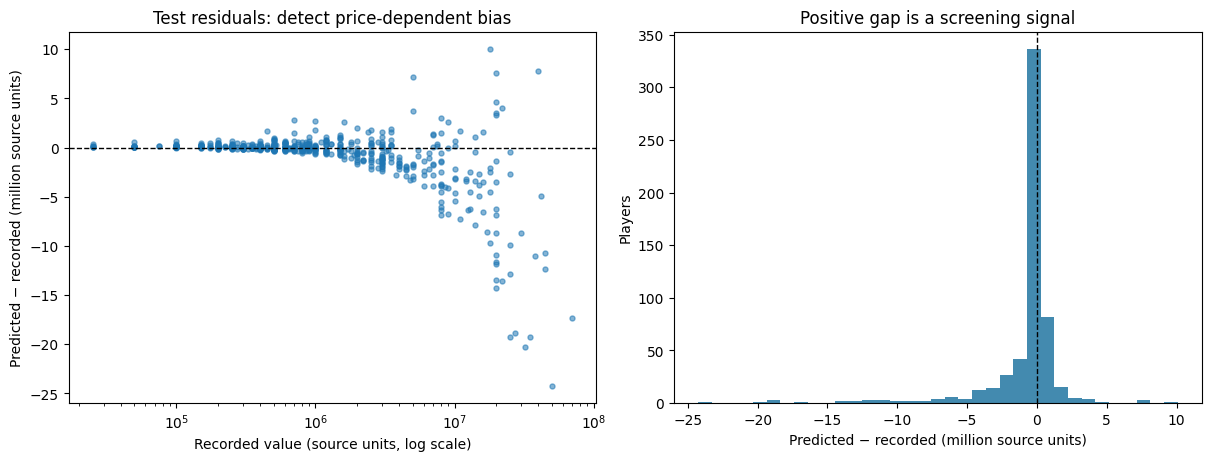

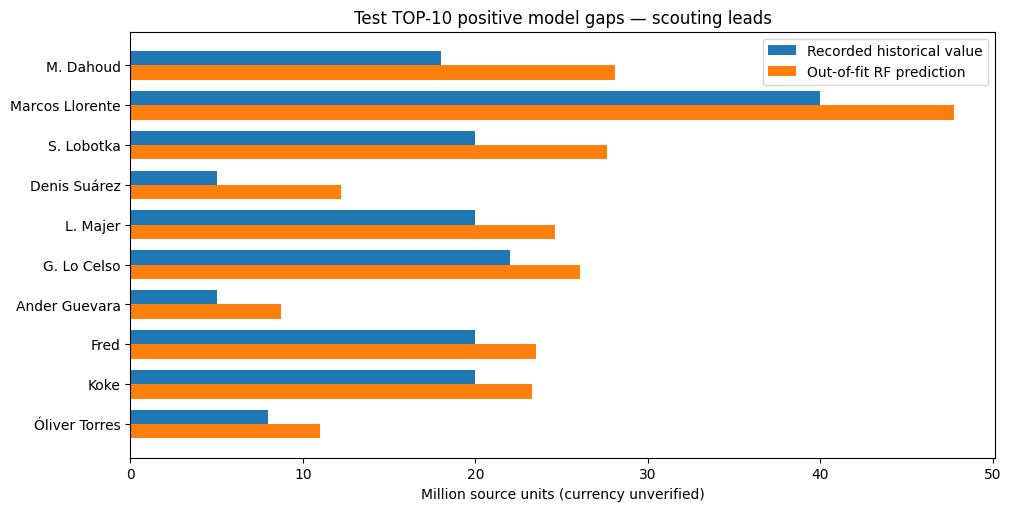

In [6]:
def rank_gaps(frame):
    return frame.sort_values(["value_gap","fifa_id"],ascending=[False,True]).reset_index(drop=True).assign(gap_rank=lambda d:np.arange(1,len(d)+1))
heldout=rank_gaps(heldout);oof=rank_gaps(oof)
columns=["fifa_id","short_name","age_at_cutoff","tm_market_value","market_value_date","predicted_value","value_gap","value_gap_fraction","predicted_to_recorded_ratio","prediction_origin"]
top=heldout.loc[heldout.positive_model_gap].head(10)
display(top[columns].round(3))
display(heldout.loc[heldout.positive_model_gap].sort_values("value_gap_fraction",ascending=False)[columns].head(10).round(3))
for name,frame in {"test_value_gaps":heldout,"train_nested_oof_value_gaps":oof,"all_out_of_fit_predictions":all_gaps,
                   "test_positive_gap_top10":top,"train_positive_gap_top10":oof.loc[oof.positive_model_gap].head(10)}.items():
    frame.to_csv(OUT/f"{name}.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].scatter(heldout.tm_market_value,heldout.value_gap/1e6,s=13,alpha=.55)
axes[0].set(xscale="log",xlabel="Recorded value (source units, log scale)",ylabel="Predicted − recorded (million source units)",title="Test residuals: detect price-dependent bias")
axes[0].axhline(0,color="black",ls="--",lw=1)
axes[1].hist(heldout.value_gap/1e6,bins=35,color="#438aaf")
axes[1].axvline(0,color="black",ls="--",lw=1)
axes[1].set(xlabel="Predicted − recorded (million source units)",ylabel="Players",title="Positive gap is a screening signal")
show(fig,"02_signed_value_gaps")
fig,ax=plt.subplots(figsize=(10,5))
pos=np.arange(len(top)); ax.barh(pos-.18,top.tm_market_value/1e6,height=.36,label="Recorded historical value")
ax.barh(pos+.18,top.predicted_value/1e6,height=.36,label="Out-of-fit RF prediction")
ax.set_yticks(pos,top.short_name);ax.invert_yaxis();ax.legend()
ax.set(xlabel="Million source units (currency unverified)",title="Test TOP-10 positive model gaps — scouting leads")
show(fig,"03_positive_gap_candidates")


## 6. Признаки и неоднородность ошибок

Permutation importance: увеличение test log-MAE после перемешивания одного **сырого** входа, 5 повторов. Связанные признаки делят важность; это не причинный эффект и не основание пересобрать v1 по test. Ошибки по стоимости и возрасту выявляют зоны систематического смещения. Границы стоимостных групп получены только из train.


,feature,increase_log_MAE,repeat_sd
3,skill_ball_control,0.314678,0.018829
18,age_at_cutoff,0.164790,0.007501
7,movement_reactions,0.085085,0.005578
0,attacking_short_passing,0.076042,0.001628
4,skill_dribbling,0.040008,0.004102
14,defending_standing_tackle,0.035096,0.002893
9,power_stamina,0.021048,0.003643
26,league_id,0.020773,0.001439
12,mentality_interceptions,0.016254,0.003067
13,defending_marking_awareness,0.012285,0.002816


,grouping,group,rows,MAE,RMSE,R2_raw,MAE_log,R2_log,median_multiplicative_error,mean_gap
0,price_band,Q1 low,154,1.425335e+05,1.984449e+05,-3.416636,0.616075,-0.432242,1.666490,1.089555e+05
1,price_band,Q2,150,2.413118e+05,4.057235e+05,-8.954941,0.380817,-3.595185,1.365268,8.881261e+04
2,price_band,Q3,102,5.705959e+05,7.699237e+05,-2.355723,0.422399,-2.253332,1.409475,-1.243469e+04
3,price_band,Q4 high,172,3.806371e+06,5.827641e+06,0.692561,0.502128,0.398250,1.478861,-2.864249e+06
4,age_band,≤23,172,8.742139e+05,2.444255e+06,0.604953,0.638058,0.700013,1.678508,-6.371566e+05
5,age_band,23–28,219,1.850528e+06,3.783902e+06,0.833910,0.424840,0.883132,1.433374,-1.064339e+06
6,age_band,>28,187,1.151941e+06,3.076010e+06,0.791892,0.420656,0.854109,1.400512,-6.477912e+05


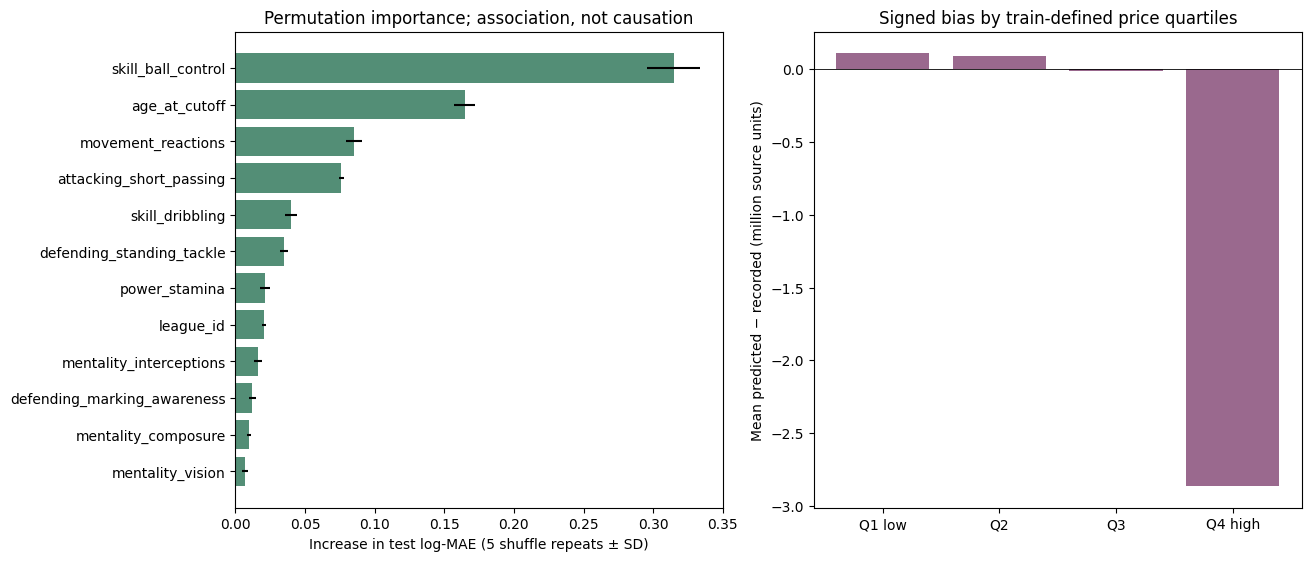

In [7]:
importance=permutation_importance(model.estimator_,Xt,yt,scoring=scorer,n_repeats=5,random_state=SEED,n_jobs=1)
importances=pd.DataFrame({"feature":FEATURES,"increase_log_MAE":importance.importances_mean,"repeat_sd":importance.importances_std}).sort_values("increase_log_MAE",ascending=False)
importances.to_csv(REPORT/"permutation_importance.csv",index=False)
display(importances.head(12))
diagnostic=test.copy();diagnostic["prediction"]=pred
diagnostic["price_band"]=pd.cut(diagnostic.tm_market_value,[-np.inf,*np.quantile(y,[.25,.5,.75]),np.inf],labels=["Q1 low","Q2","Q3","Q4 high"])
diagnostic["age_band"]=pd.cut(diagnostic.age_at_cutoff,[0,23,28,100],labels=["≤23","23–28",">28"])
groups=[]
for kind in ["price_band","age_band"]:
    for group,part in diagnostic.groupby(kind,observed=True):
        groups.append({"grouping":kind,"group":str(group),"rows":len(part),**metrics(part.tm_market_value.to_numpy(),part.prediction.to_numpy())})
group_metrics=pd.DataFrame(groups)
group_metrics.to_csv(REPORT/"test_cohort_diagnostics.csv",index=False)
display(group_metrics)
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
imp=importances.head(12).iloc[::-1]
axes[0].barh(imp.feature,imp.increase_log_MAE,xerr=imp.repeat_sd,color="#538e76")
axes[0].axvline(0,color="black",lw=.6)
axes[0].set(xlabel="Increase in test log-MAE (5 shuffle repeats ± SD)",title="Permutation importance; association, not causation")
gm=group_metrics.loc[group_metrics.grouping.eq("price_band")]
axes[1].bar(gm.group,gm.mean_gap/1e6,color="#9a698e")
axes[1].axhline(0,color="black",lw=.6)
axes[1].set(ylabel="Mean predicted − recorded (million source units)",title="Signed bias by train-defined price quartiles")
show(fig,"04_importance_and_price_bias")


## 7. Устойчивость скрининга при изменении train

Десять повторных RF fit с теми же выбранными параметрами, но на случайных 80% train; test всегда исключён. Проверяем знак gap и пересечение TOP-10. Это **анализ чувствительности к подвыборке и seed**, не калиброванный доверительный или прогнозный интервал. Не используем квантили деревьев как гарантированную неопределённость цены.


,fifa_id,short_name,tm_market_value,primary_prediction,positive_gap_frequency_10_subsamples,subsample_prediction_sd
0,218339,M. Dahoud,18000000.0,2.807646e+07,1.0,2.805115e+06
1,226161,Marcos Llorente,40000000.0,4.775715e+07,0.8,3.549007e+06
2,216435,S. Lobotka,20000000.0,2.760857e+07,1.0,1.927223e+06
3,205192,Denis Suárez,5000000.0,1.222901e+07,1.0,1.398826e+06
4,244261,L. Majer,20000000.0,2.463935e+07,1.0,2.131157e+06
5,226226,G. Lo Celso,22000000.0,2.603958e+07,1.0,2.344244e+06
6,240458,Ander Guevara,5000000.0,8.722719e+06,1.0,7.101793e+05
7,209297,Fred,20000000.0,2.351146e+07,0.7,2.990118e+06
8,193747,Koke,20000000.0,2.328723e+07,0.5,2.866665e+06
9,208777,Óliver Torres,8000000.0,1.097396e+07,1.0,1.146840e+06


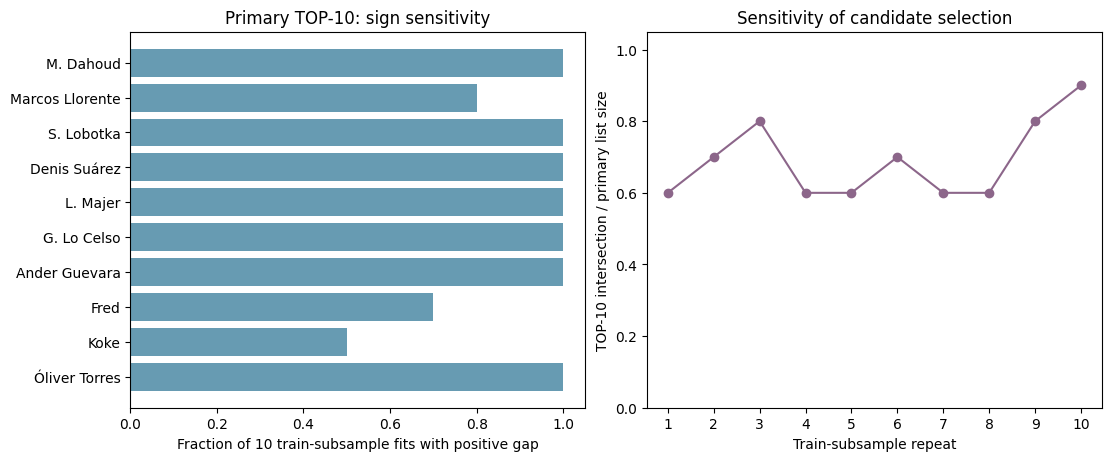

In [8]:
rep_predictions=[];overlaps=[]
primary_top=set(top.fifa_id)
for repeat in range(10):
    subset=train.sample(frac=.8,random_state=SEED+repeat)
    rep_model=MarketValuePredictor(**selected,random_state=SEED+repeat).fit(subset)
    rp=rep_model.predict(test);rep_predictions.append(rp)
    ranked=rank_gaps(rep_model.gap_table(test))
    alternate=set(ranked.loc[ranked.positive_model_gap].head(10).fifa_id)
    overlaps.append(len(primary_top&alternate)/max(1,len(primary_top)))
rep_matrix=np.array(rep_predictions)
stability=test[["fifa_id","short_name","tm_market_value"]].copy()
stability["primary_prediction"]=pred
stability["positive_gap_frequency_10_subsamples"]=(rep_matrix>yt).mean(axis=0)
stability["subsample_prediction_sd"]=rep_matrix.std(axis=0,ddof=1)
stability.to_csv(OUT/"test_gap_sensitivity.csv",index=False)
top_stability=top[["fifa_id","short_name"]].merge(stability.drop(columns="short_name"),on="fifa_id",validate="one_to_one")
display(top_stability)
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
axes[0].barh(top_stability.short_name,top_stability.positive_gap_frequency_10_subsamples,color="#679bb2")
axes[0].invert_yaxis();axes[0].set(xlim=(0,1.05),xlabel="Fraction of 10 train-subsample fits with positive gap",title="Primary TOP-10: sign sensitivity")
axes[1].plot(np.arange(1,11),overlaps,"o-",color="#8c668a")
axes[1].set(ylim=(0,1.05),xticks=np.arange(1,11),xlabel="Train-subsample repeat",ylabel="TOP-10 intersection / primary list size",title="Sensitivity of candidate selection")
show(fig,"05_gap_sensitivity")


## 8. Сохранение модели, проверки и вывод

Сохраняется модель, обученная **только на train**, с fold-local preprocessing. Для нового исторического CM: `model.predict(profiles)`; для сравнения с записанной ценой: `model.gap_table(profiles)` — метод отвергает обучающие ID. Для train доступны только вложенные OOF прогнозы. Joblib загружаем только из собственного доверенного файла.

Ограничения: отобранная matched-CM когорта; неполнота факторов; давность части оценок до 365 дней; игровой источник характеристик; условные интервалы; ранее исследованный test; log-target shrinkage; разные происхождения OOF/test. Модель объясняет наблюдаемую цену этого среза, а не доказывает доступность или справедливую трансферную цену.


In [9]:
bundle=OUT/"market_value_rf_2022-09-26.joblib"
joblib.dump(model,bundle)
loaded=joblib.load(bundle)
assert np.allclose(loaded.predict(test),pred)
rejected_in_sample=False
try: model.gap_table(train.head(1))
except ValueError: rejected_in_sample=True
checks={"source_hash_verified":sha(source)==fm["outputs"][source.name]["sha256"],
        "27_allowlisted_inputs":len(FEATURES)==27,"disjoint_train_test":not bool(set(train.fifa_id)&set(test.fifa_id)),
        "one_out_of_fit_prediction_per_player":len(all_gaps)==2886 and all_gaps.fifa_id.is_unique,
        "gap_sign_correct":bool(np.allclose(all_gaps.value_gap,all_gaps.predicted_value-all_gaps.tm_market_value)),
        "all_predictions_nonnegative_finite":bool(np.isfinite(all_gaps.predicted_value).all() and all_gaps.predicted_value.ge(0).all()),
        "in_sample_gap_rejected":rejected_in_sample,"bundle_roundtrip":bool(np.allclose(loaded.predict(test),pred))}
assert all(checks.values()),checks
summary={"cutoff":fm["cutoff"],"rows":len(data),"train_rows":len(train),"test_rows":len(test),"features":FEATURES,
         "target":"log1p(tm_market_value), inverse expm1; original source units, currency unverified",
         "selected_rf_parameters":selected,"n_estimators":160,"ridge_alpha":ridge_search.best_params_["regressor__ridge__alpha"],
         "test_metrics":evaluation.to_dict(orient="index"),"nested_oof_train_metrics":oof_metrics,
         "paired_ridge_minus_rf_log_mae_ci95":paired_ci,"test_positive_gaps":int(heldout.positive_model_gap.sum()),
         "train_oof_positive_gaps":int(oof.positive_model_gap.sum()),"top10_subsample_overlap_mean":float(np.mean(overlaps)),
         "test_top10_positive_sign_frequency_mean":float(top_stability.positive_gap_frequency_10_subsamples.mean()),
         "train_ids_sha256":ids_hash(train.fifa_id),"test_ids_sha256":ids_hash(test.fifa_id),
         "source_sha256":sha(source),"model_sha256":sha(bundle),"sklearn_version":sklearn.__version__,
         "validation":{k:bool(v) for k,v in checks.items()},"figures":figures,
         "limitations":"Explored test; matched cohort; unobserved factors; log-inverse bias; model gap is not fair value or transfer-success evidence."}
(REPORT/"valuation_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")
outputs={p.name:sha(p) for p in sorted(OUT.iterdir()) if p.is_file() and p.name!="prediction_manifest.json"}
(OUT/"prediction_manifest.json").write_text(json.dumps({"source_sha256":sha(source),"cutoff":fm["cutoff"],"outputs":outputs,
        "main_model_fit":"2308 train IDs only","train_prediction_protocol":"nested 5 outer x 3 inner CV; no own target in fit or selection"},indent=2),encoding="utf-8")
rf=evaluation.loc["Random Forest log"];ridge=evaluation.loc["Ridge log"];dummy=evaluation.loc["Train median"]
lines=["# Model 3 — Market Value Prediction","",f"Исторический срез: {fm['cutoff']}; 2886 CM, 2308 train / 578 test. 27 входов Feature Set v1.",
       "", "## Модель и оценка","",f"Random Forest: 160 деревьев, параметры {selected}; target log1p стоимости. Imputation/encoding — только внутри fit folds. Train-only 3-fold CV; Ridge alpha={summary['ridge_alpha']}.",
       "",f"Test RF: MAE={rf.MAE:,.0f}, RMSE={rf.RMSE:,.0f} исходных единиц; R²(raw)={rf.R2_raw:.3f}; MAE(log)={rf.MAE_log:.3f}; R²(log)={rf.R2_log:.3f}; медианный multiplicative error={rf.median_multiplicative_error:.2f}×.",
       "",f"MAE(log): train median={dummy.MAE_log:.3f}, Ridge={ridge.MAE_log:.3f}, RF={rf.MAE_log:.3f}. Paired test bootstrap CI для Ridge minus RF: [{paired_ci[0]:.4f}, {paired_ci[1]:.4f}]. Условные интервалы не являются новой независимой проверкой.",
       "",comparison_note,
       "", "## Прогнозы и gap","",f"Для всех 2886 игроков сохранены прогнозы вне собственного fit: 2308 nested OOF (5×3 CV) и 578 test от train-only модели. Test positive gaps: {summary['test_positive_gaps']}; train OOF: {summary['train_oof_positive_gaps']}.",
       "",f"Среднее пересечение test TOP-10 при 10 fit на 80% train: {np.mean(overlaps):.1%}. Средняя частота положительного знака для основного TOP-10: {top_stability.positive_gap_frequency_10_subsamples.mean():.1%}. Это чувствительность, не прогнозный интервал.",
       "", "ValueGap = PredictedValue − MarketValue. Большой положительный gap — исследовательский скаутинговый сигнал. Абсолютные и относительные gaps имеют разные перекосы; списки OOF и test ранжируются отдельно. Цена не добавлена в KNN/K-Means.",
       "", "## Артефакты","", "Notebook: `notebooks/07_market_value_prediction.ipynb`; модуль: `src/valuation.py`; тесты: `tests/test_valuation.py`. Модель, per-player gaps, fold ID audit и manifest находятся в gitignored `data/processed/valuation/`. Агрегаты и пять PNG/SVG фигур: `reports/valuation/`.",
       "", "## Пределы вывода","", "Прогноз не объективная справедливая цена. Неизвестны контракты, травмы, спрос и другие факторы. Историческая стоимость не цена трансфера. Валюта архива не подтверждена; значения в исходных единицах. Оценки могут отставать от среза на 365 дней. Log-inversion не даёт арифметическое условное среднее и может недооценивать дорогих игроков. Test уже изучался в EDA; новый сезон/независимая выборка нужны для подтверждающих выводов. Streamlit starter не интегрирован с этим модулем."]
(ROOT/"docs/market_value_prediction.md").write_text("\n".join(lines)+"\n",encoding="utf-8")
display(pd.Series(checks,name="passed"))
display(Markdown(f"**Готово:** RF test MAE(log)={rf.MAE_log:.3f}; raw MAE={rf.MAE:,.0f} исходных единиц. "
                 f"Все {len(all_gaps)} price gaps рассчитаны вне собственного fit. Положительный gap — сигнал для проверки, не справедливая цена."))


source_hash_verified                    True
27_allowlisted_inputs                   True
disjoint_train_test                     True
one_out_of_fit_prediction_per_player    True
gap_sign_correct                        True
all_predictions_nonnegative_finite      True
in_sample_gap_rejected                  True
bundle_roundtrip                        True
Name: passed, dtype: bool

**Готово:** RF test MAE(log)=0.487; raw MAE=1,333,985 исходных единиц. Все 2886 price gaps рассчитаны вне собственного fit. Положительный gap — сигнал для проверки, не справедливая цена.